# Data Preprocessing

## Contents

1. Understanding the data
2. Removing unnecessary data
3. Missing values
4. Outliers
5. Standardization and normalization
6. Encoding categorical variables
7. Revision

## Dataset

[Salary dataset](https://github.com/BouhamedMohammedMounir/Machine-learning-course/blob/master/salaries.csv)

The dataset was adapted for preprocessing exercises by adding missing values,
duplicate rows and extreme salaries. The examples use `salary_in_usd` to
compare salaries in the same currency.

Enable Internet access and run the cells in order.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OrdinalEncoder

pd.set_option("display.max_columns", None)

### Load the dataset

In [ ]:
revision = pd.read_csv(
    "https://raw.githubusercontent.com/"
    "mwaskom/seaborn-data/master/titanic.csv"
)

data = revision.copy()
raw_data = data.copy()

print("Shape:", data.shape)
data.head()

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 1. Understanding the data

In [ ]:
data.shape

(891, 15)

In [ ]:
data.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [ ]:
data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
data.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [ ]:
data.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
data.describe(include="object")

,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


### Unique values in categorical columns

In [ ]:
categorical_columns = data.select_dtypes(include="object").columns

for column in categorical_columns:
    print(column, ":", data[column].nunique(), "unique values")

sex : 2 unique values
embarked : 3 unique values
class : 3 unique values
who : 3 unique values
deck : 7 unique values
embark_town : 3 unique values
alive : 2 unique values


## 2. Removing unnecessary data

### Duplicate rows

Find exact duplicate rows, then remove them.

In [ ]:
data.duplicated().sum()

np.int64(107)

In [ ]:
rows_before = len(data)
data = data.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", rows_before - len(data))
data.shape

Duplicate rows removed: 107


(784, 15)

### Missing values

In [ ]:
missing_values = data.isnull().sum()

missing_table = pd.DataFrame({
    "Missing values": missing_values,
    "Percentage": missing_values / len(data) * 100
})

missing_table.sort_values("Percentage", ascending=False).round(2)

,Missing values,Percentage
deck,582,74.23
age,106,13.52
embarked,2,0.26
embark_town,2,0.26
sex,0,0.00
pclass,0,0.00
survived,0,0.00
fare,0,0.00
parch,0,0.00
sibsp,0,0.00


Remove columns with **70% or more** missing values.

In [ ]:
missing_threshold = 70

columns_to_remove = missing_table[
    missing_table["Percentage"] >= missing_threshold
].index.tolist()

print(columns_to_remove)


['deck']


In [ ]:
data = data.drop(columns=columns_to_remove)
print("Columns removed:", columns_to_remove)
data.shape

Columns removed: ['deck']


(784, 14)

### Rows with missing values

Compare removing every incomplete row with removing only rows that lack
`salary_in_usd`. Store the results in separate copies so that `data` still
contains missing values for the imputation examples.

For a salary prediction task, remove rows with a missing target rather
than imputing the target value.

In [ ]:
complete_rows = data.dropna()

salary_rows = data.dropna(subset=["survived"])

row_removal_comparison = pd.DataFrame({
    "Rows kept": [
        len(data),
        len(complete_rows),
        len(salary_rows)
    ],
    "Rows removed": [
        0,
        len(data) - len(complete_rows),
        len(data) - len(salary_rows)
    ]
}, index=[
    "Before row removal",
    "Remove every incomplete row",
    "Remove rows missing survived"
])

row_removal_comparison

,Rows kept,Rows removed
Before row removal,784,0
Remove every incomplete row,676,108
Remove rows missing survived,784,0


## 3. Handling missing values

In [ ]:
data.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,106
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


### Numerical variables

Mean:

$$
\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i
$$

The median is less sensitive to extreme values.

In [ ]:
numeric_columns = data.select_dtypes(include=np.number).columns
numeric_columns

Index(['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare'], dtype='object')

#### Mean imputation

Use a copy of the data to compare mean and median imputation.

In [ ]:
mean_example = data.copy()

numeric_columns = data.select_dtypes(
    include=np.number
).columns

for column in numeric_columns:
    mean_example[column] = mean_example[column].fillna(
        mean_example[column].mean()
    )

mean_example[numeric_columns].isnull().sum()

,0
survived,0
pclass,0
age,0
sibsp,0
parch,0
fare,0


#### Median imputation

In [ ]:
numerical_missing_before = data[numeric_columns].isnull().sum()

for column in numeric_columns:
    data[column] = data[column].fillna(data[column].median())

pd.DataFrame({
    "Missing before": numerical_missing_before,
    "Missing after": data[numeric_columns].isnull().sum()
})

,Missing before,Missing after
survived,0,0
pclass,0,0
age,106,0
sibsp,0,0
parch,0,0
fare,0,0


### Categorical variables

Replace missing values with the mode, the most frequent category.

In [ ]:
categorical_columns = data.select_dtypes(include="object").columns
categorical_missing_before = data[categorical_columns].isnull().sum()

for column in categorical_columns:
    if data[column].isnull().any():
        data[column] = data[column].fillna(data[column].mode()[0])

pd.DataFrame({
    "Missing before": categorical_missing_before,
    "Missing after": data[categorical_columns].isnull().sum()
})

,Missing before,Missing after
sex,0,0
embarked,2,0
class,0,0
who,0,0
embark_town,2,0
alive,0,0


## 4. Outlier detection and treatment

### Interquartile range

$$
\mathrm{IQR} = Q_3 - Q_1
$$

Flag values outside these limits:

$$
L = Q_1 - 1.5\,\mathrm{IQR}, \qquad U = Q_3 + 1.5\,\mathrm{IQR}
$$

Use `salary_in_usd` because `salary` contains amounts in different currencies.

In [ ]:
outlier_columns = ["fare"]

Q1 = data[outlier_columns].quantile(0.25)
Q3 = data[outlier_columns].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Lower bound": lower_bound,
    "Upper bound": upper_bound,
})

,Q1,Q3,IQR,Lower bound,Upper bound
fare,8.05,34.10935,26.05935,-31.039025,73.198375


In [ ]:
outlier_count = {}

for column in outlier_columns:
    condition = (
        (data[column] < lower_bound[column]) |
        (data[column] > upper_bound[column])
    )
    outlier_count[column] = condition.sum()

pd.Series(outlier_count, name="Outliers")

,Outliers
fare,102


### Box plot

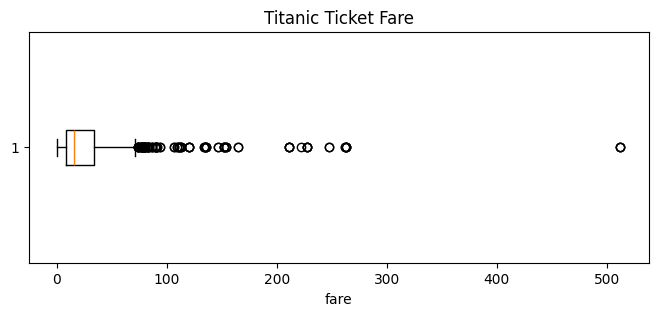

In [ ]:
plt.figure(figsize=(8, 3))

plt.boxplot(data["fare"], vert=False)

plt.xlabel("fare")
plt.title("Titanic Ticket Fare")

plt.show()

Cap `salary_in_usd` at the IQR limits. Review flagged values before applying
capping to a real dataset, since some extreme salaries may be valid.

In [ ]:
fare_q1 = data["fare"].quantile(0.25)
fare_q3 = data["fare"].quantile(0.75)

fare_iqr = fare_q3 - fare_q1

fare_lower = fare_q1 - 1.5 * fare_iqr
fare_upper = fare_q3 + 1.5 * fare_iqr

data_capped = data.copy()

data_capped["fare"] = data_capped["fare"].clip(
    lower=fare_lower,
    upper=fare_upper
)

print("Outliers before capping:",
      ((data["fare"] < fare_lower) |
       (data["fare"] > fare_upper)).sum())

print("Outliers after capping:",
      ((data_capped["fare"] < fare_lower) |
       (data_capped["fare"] > fare_upper)).sum())

data_capped["fare"].describe()

Outliers before capping: 102
Outliers after capping: 0


,fare
count,784.000000
mean,26.492784
std,22.762166
min,0.000000
25%,8.050000
50%,15.900000
75%,34.109350
max,73.198375


## 5. Standardization and normalization

### Standardization

$$
z = \frac{x - \mu}{\sigma}
$$

For prediction tasks, fit preprocessing on the training data and use the same
parameters for the test data. Exclude `salary_in_usd` and `salary` from the
input features if `salary_in_usd` is the prediction target.

In [ ]:
numeric_columns = [
    "age",
    "sibsp",
    "parch",
    "fare"
]

standard_scaler = StandardScaler()

standardized_data = data_capped.copy()

standardized_data[numeric_columns] = (
    standard_scaler.fit_transform(
        data_capped[numeric_columns]
    )
)

standardized_data[numeric_columns].head()

,age,sibsp,parch,fare
0,-0.557360,0.484009,-0.497157,-0.845924
1,0.608298,0.484009,-0.497157,1.969018
2,-0.265945,-0.530599,-0.497157,-0.816251
3,0.389737,0.484009,-0.497157,1.169669
4,0.389737,-0.530599,-0.497157,-0.810756


### Min-max normalization

$$
x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$$

In [ ]:
minmax_scaler = MinMaxScaler()

normalized_data = data_capped.copy()
normalized_data[numeric_columns] = minmax_scaler.fit_transform(
    data_capped[numeric_columns]
)

normalized_data[numeric_columns].head()

,age,sibsp,parch,fare
0,0.271174,0.125,0.0,0.099046
1,0.472229,0.125,0.0,0.973837
2,0.321438,0.000,0.0,0.108267
3,0.434531,0.125,0.0,0.725426
4,0.434531,0.000,0.0,0.109975


## 6. Encoding categorical variables

### Label encoding

Assign an integer to each job title. These codes identify categories and do
not imply a ranking.

In [ ]:
label_encoder = LabelEncoder()

sex_encoded = data_capped[["sex"]].copy()

sex_encoded["sex_code"] = label_encoder.fit_transform(
    sex_encoded["sex"]
)

sex_encoded.drop_duplicates()

,sex,sex_code
0,male,1
1,female,0


### Ordinal encoding

Encode experience levels in this order:

$\mathrm{EN} < \mathrm{MI} < \mathrm{SE} < \mathrm{EX}$

In [ ]:
ordinal_encoder = OrdinalEncoder(
    categories=[["First", "Second", "Third"]]
)

class_encoded = data_capped[["class"]].copy()

class_encoded["class_code"] = ordinal_encoder.fit_transform(
    class_encoded[["class"]]
)

class_encoded.drop_duplicates()

,class,class_code
0,Third,2.0
1,First,0.0
9,Second,1.0


### One-hot encoding

Create a binary column for each employment type.

In [ ]:
embarked_encoded = pd.get_dummies(
    data_capped["embarked"],
    prefix="embarked",
    dtype=int
)

embarked_examples = pd.concat(
    [data_capped[["embarked"]], embarked_encoded],
    axis=1
)

embarked_examples.drop_duplicates()

,embarked,embarked_C,embarked_Q,embarked_S
0,S,0,0,1
1,C,1,0,0
5,Q,0,1,0


Join the encoded columns to the DataFrame.

In [ ]:
encoded_data = pd.concat(
    [
        data_capped.drop(columns=["embarked"]),
        embarked_encoded
    ],
    axis=1
)

encoded_data.head()

,survived,pclass,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,embarked_C,embarked_Q,embarked_S
0,0,3,male,22.0,1,0,7.2500,Third,man,True,Southampton,no,False,0,0,1
1,1,1,female,38.0,1,0,71.2833,First,woman,False,Cherbourg,yes,False,1,0,0
2,1,3,female,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True,0,0,1
3,1,1,female,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False,0,0,1
4,0,3,male,35.0,0,0,8.0500,Third,man,True,Southampton,no,True,0,0,1


## 7. Revision

1. Show the dimensions.
2. Display the first five rows.
3. Identify duplicated rows.
4. Remove duplicates.
5. Calculate missing-value percentages.
6. Remove columns with at least 70% missing values.
7. Compare the two row-deletion methods using separate copies.
8. Fill numerical missing values with the median.
9. Fill categorical missing values with the mode.
10. Detect salary outliers using IQR.
11. Cap salary values using those limits.
12. Standardize numerical variables.
13. One-hot encode `employment_type`.

### Solution

In [ ]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

revision = pd.read_csv(
    "https://raw.githubusercontent.com/"
    "mwaskom/seaborn-data/master/titanic.csv"
)

print("Shape:", revision.shape)
print(revision.head())

print("Duplicated rows:", revision.duplicated().sum())

revision = revision.drop_duplicates().reset_index(drop=True)

missing_percentage = revision.isnull().mean() * 100

print(missing_percentage.sort_values(ascending=False))

revision = revision.drop(
    columns=missing_percentage[
        missing_percentage >= 70
    ].index
)

complete_revision = revision.dropna()

survived_revision = revision.dropna(
    subset=["survived"]
)

print("Complete rows:", len(complete_revision))
print("Rows with survived:", len(survived_revision))

num_cols = revision.select_dtypes(
    include=np.number
).columns

cat_cols = revision.select_dtypes(
    include="object"
).columns

for col in num_cols:
    revision[col] = revision[col].fillna(
        revision[col].median()
    )

for col in cat_cols:
    if revision[col].isnull().any():
        revision[col] = revision[col].fillna(
            revision[col].mode()[0]
        )

q1 = revision["fare"].quantile(0.25)
q3 = revision["fare"].quantile(0.75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = revision[
    (revision["fare"] < lower) |
    (revision["fare"] > upper)
]

print("Outliers before capping:", len(outliers))

revision["fare"] = revision["fare"].clip(
    lower=lower,
    upper=upper
)

numeric_features = [
    "age",
    "sibsp",
    "parch",
    "fare"
]

scaler = StandardScaler()

revision[numeric_features] = scaler.fit_transform(
    revision[numeric_features]
)

revision = pd.get_dummies(
    revision,
    columns=["sex", "embarked"],
    dtype=int
)

print("Remaining missing values:",
      revision.isnull().sum().sum())

revision.head()

Shape: (891, 15)
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
Duplicated rows: 107
deck           74.234694
age            13.520408
embarked        0.255102
embark_town     0.255102
sex             0.000000
pclass          0.000000
survived        0.000000
fare  

,survived,pclass,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,0,3,-0.557360,0.484009,-0.497157,-0.845924,Third,man,True,Southampton,no,False,0,1,0,0,1
1,1,1,0.608298,0.484009,-0.497157,1.969018,First,woman,False,Cherbourg,yes,False,1,0,1,0,0
2,1,3,-0.265945,-0.530599,-0.497157,-0.816251,Third,woman,False,Southampton,yes,True,1,0,0,0,1
3,1,1,0.389737,0.484009,-0.497157,1.169669,First,woman,False,Southampton,yes,False,1,0,0,0,1
4,0,3,0.389737,-0.530599,-0.497157,-0.810756,Third,man,True,Southampton,no,True,0,1,0,0,1


In [ ]:
print("Shape:", revision.shape)

print("Missing values:", revision.isnull().sum().sum())

print("Columns:", revision.columns.tolist())

display(revision.head())

Shape: (784, 17)
Missing values: 0
Columns: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone', 'sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S']


,survived,pclass,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,0,3,-0.557360,0.484009,-0.497157,-0.845924,Third,man,True,Southampton,no,False,0,1,0,0,1
1,1,1,0.608298,0.484009,-0.497157,1.969018,First,woman,False,Cherbourg,yes,False,1,0,1,0,0
2,1,3,-0.265945,-0.530599,-0.497157,-0.816251,Third,woman,False,Southampton,yes,True,1,0,0,0,1
3,1,1,0.389737,0.484009,-0.497157,1.169669,First,woman,False,Southampton,yes,False,1,0,0,0,1
4,0,3,0.389737,-0.530599,-0.497157,-0.810756,Third,man,True,Southampton,no,True,0,1,0,0,1


## Summary

- Inspect the data.
- Remove duplicate rows and very incomplete columns.
- Compare deleting incomplete rows with imputing missing values.
- Impute numerical and categorical missing values.
- Detect and treat outliers.
- Standardize or normalize numerical variables.
- Encode categorical variables.

## References

- [Course dataset](https://github.com/BouhamedMohammedMounir/Machine-learning-course/blob/master/salaries.csv)
- [aijobs.net salary dataset](https://github.com/foorilla/ai-jobs-net-salaries), CC0-1.0.